### IT5092 – Neuroscience & Neurocomputing
### Lab 01 (Week 1): EEG Rhythms & Behavioural State Inference (Guided)

**Type:** Individual Lab  
**Duration:** 2 hours
**Submission:** One `.ipynb` file 

---
#### Learning Outcomes
By the end of this lab, you will be able to:
1. Load and inspect a real EEG dataset programmatically
2. Perform basic EEG preprocessing (channel selection, filtering, referencing)
3. Compute Power Spectral Density (PSD) and band power features (delta/theta/alpha/beta/gamma)
4. Test a neuroscience hypothesis computationally by comparing alpha-band activity across different brain states (e.g., eyes open vs eyes closed).
5. Write a short scientific-style interpretation connecting rhythms ↔ brain state ↔ behaviour


Raw EEG signals (µV, time domain)
        ->
Preprocessing (filtering, referencing)
        ->
Frequency analysis (PSD)
        ->
Feature extraction (band power)
        ->
Interpretation (brain state / behavior)


#### 1) Install libraries

In [1]:
#pip install mne numpy scipy matplotlib

In [2]:
import mne
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
mne.set_log_level('WARNING')

In [3]:
import os

# The dataset (eeg-motor-movementimagery-dataset-1.0.0.zip) is already downloaded
# and unzipped next to this notebook, inside the folder called "files".
# That folder contains S001, S002, ... one folder per subject.
DATA_DIR = "files"


def get_edf_path(subject, run):
    """Return the path of one EDF file, e.g. files/S001/S001R01.edf"""
    subject_folder = f"S{subject:03d}"            # 1  -> S001
    file_name = f"S{subject:03d}R{run:02d}.edf"   # 1,1 -> S001R01.edf
    return os.path.join(DATA_DIR, subject_folder, file_name)


print("Example path:", get_edf_path(1, 1))
print("File exists? ", os.path.exists(get_edf_path(1, 1)))

Example path: files/S001/S001R01.edf
File exists?  True


In [4]:
# Load one subject, one run (very small)
subject = 1
run = 1          # Run 1 = baseline, EYES OPEN

raw_file = get_edf_path(subject, run)
raw = mne.io.read_raw_edf(raw_file, preload=True)

raw

<RawEDF | S001R01.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>

#### Task B1:
Load baseline run 2 (eyes closed) for comparison

In [5]:
# Task B1: load baseline Run 2 (EYES CLOSED) for comparison
run2 = 2
raw2_file = get_edf_path(subject, run2)
raw2 = mne.io.read_raw_edf(raw2_file, preload=True)

print("Run 1 (eyes open)  :", raw_file)
print("Run 2 (eyes closed):", raw2_file)
print()
print("Run 2 sampling rate:", raw2.info["sfreq"], "Hz")
print("Run 2 channels     :", len(raw2.ch_names))
print("Run 2 duration     :", round(raw2.times[-1], 1), "s")

raw2

Run 1 (eyes open)  : files/S001/S001R01.edf
Run 2 (eyes closed): files/S001/S001R02.edf

Run 2 sampling rate: 160.0 Hz
Run 2 channels     : 64
Run 2 duration     : 61.0 s


<RawEDF | S001R02.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>

#### 2) Load EEG Dataset (MNE sample)
This uses an EEG dataset shipped with MNE (it may download the first time).

160.0
64


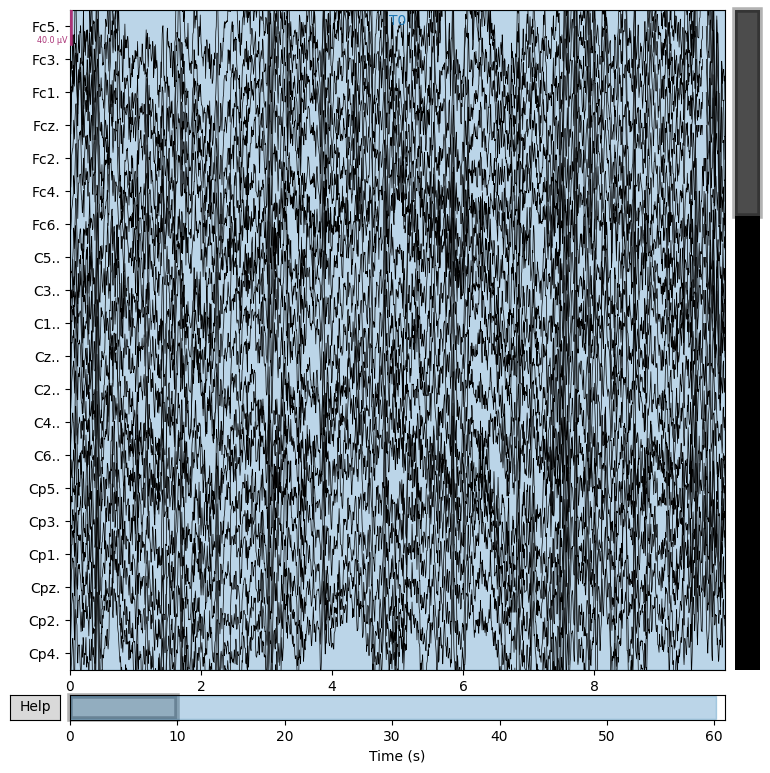

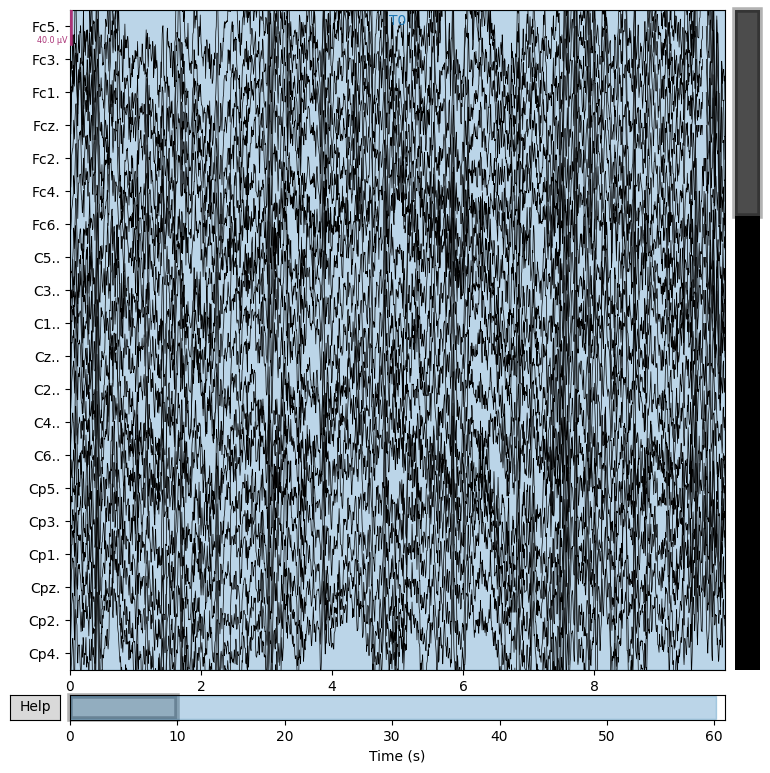

In [6]:
print(raw.info["sfreq"])      # sampling rate
print(len(raw.ch_names))      # number of channels
raw.plot(duration=10, n_channels=20)

#### Feature Types
1) Power at each frequency - EEG voltage
2) Power Spectral Density (PSD) - Power at each frequency
3) Band Power Features (Alpha,Delta,Thete,Beta,Gamma)


#### 3) Pick EEG + quick metadata
We keep EEG and EOG (eye channel) for inspection, then exclude EOG during rhythm computation.


In [7]:

raw_eeg = raw.copy().pick_types(meg=False, eeg=True, eog=True, stim=False, exclude='bads')

sfreq = raw_eeg.info['sfreq']
duration = raw_eeg.times[-1]
n_chan = len(raw_eeg.ch_names)

print(f'Sampling rate: {sfreq} Hz')
print(f'Duration: {duration:.1f} s')
print(f'Channels kept: {n_chan}')
print('First 12 channels:', raw_eeg.ch_names[:12])


Sampling rate: 160.0 Hz
Duration: 61.0 s
Channels kept: 64
First 12 channels: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..']


### Task 2: Student write-up (3–5 lines)
- What is EEG measuring (single neuron vs population)?
- Mention **two** brain rhythms and what behavioural state they relate to.


**Answer (Task 2):**

- EEG measures **populations**, not single neurons: each electrode picks up the summed post-synaptic
  potentials of millions of aligned cortical neurons. One neuron's spike is far too small to reach the scalp.
- **Alpha (8-12 Hz)** = relaxed wakefulness, strongest at the occipital area, bigger with eyes closed.
- **Beta (13-30 Hz)** = alert, active state (concentrating or moving).

#### 4) Visualize raw EEG (time domain)
Inspect ~10 seconds and identify artifacts.


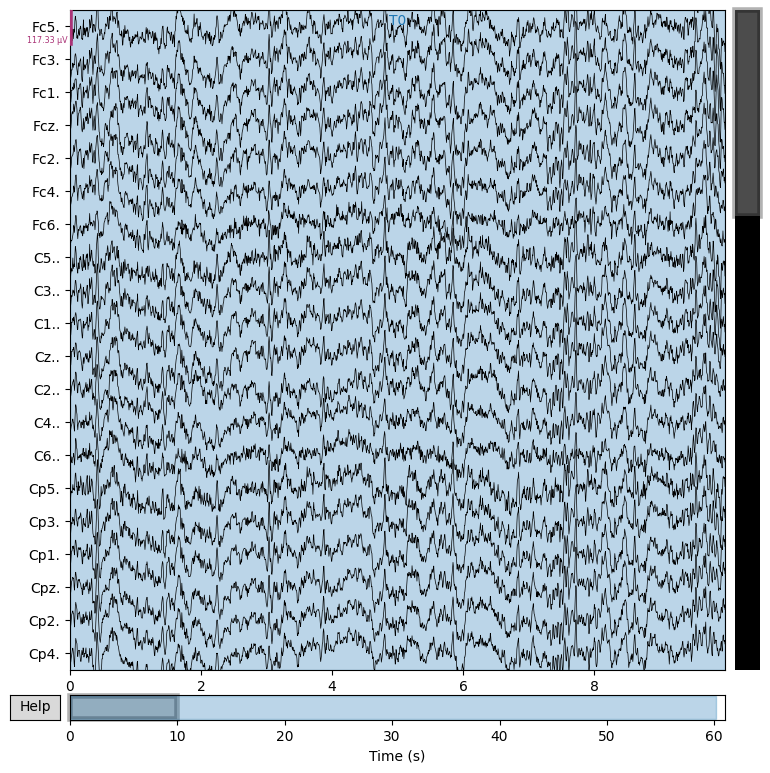

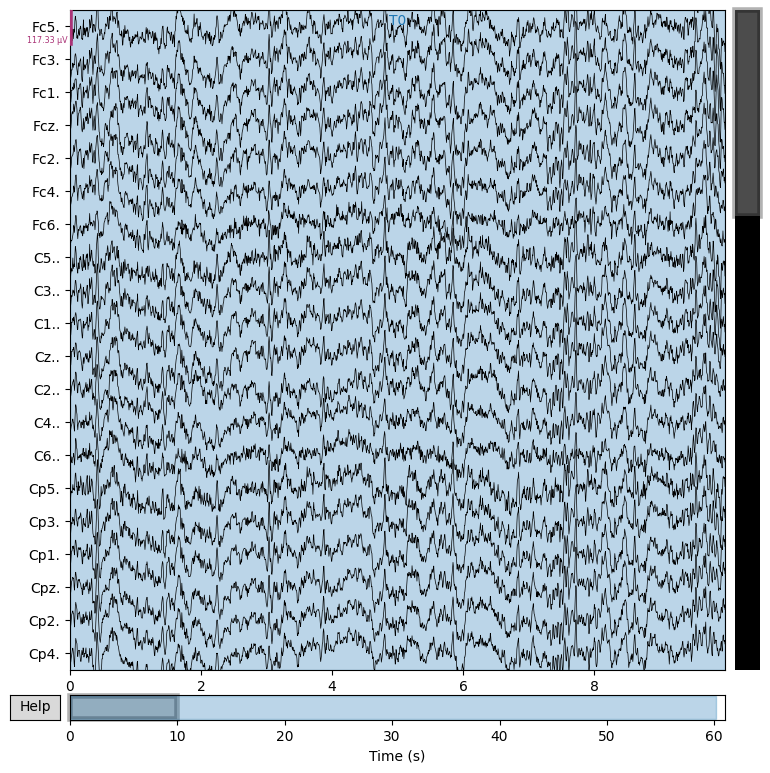

In [8]:
raw_eeg.plot(duration=10, n_channels=20, scalings='auto')


### Task 2: Student write-up
- Identify **two** artifacts you can see (e.g., blink, slow drift, muscle).


**Answer (Task 2):**

- **Eye blinks** - large sharp deflections on the frontal channels (`Fp1.`, `Fp2.`, `Af7.`, `Af8.`) around
  ~10 s, ~14 s and ~38-41 s, and almost absent at the occipital channels.
- **Slow drift** - a slow (< 1 Hz) wander of the baseline caused by sweat and electrode movement.

#### 5) Preprocessing baseline
We apply:
- Average reference
- Band-pass filter 1–45 Hz
- 50 Hz notch filter (mains)


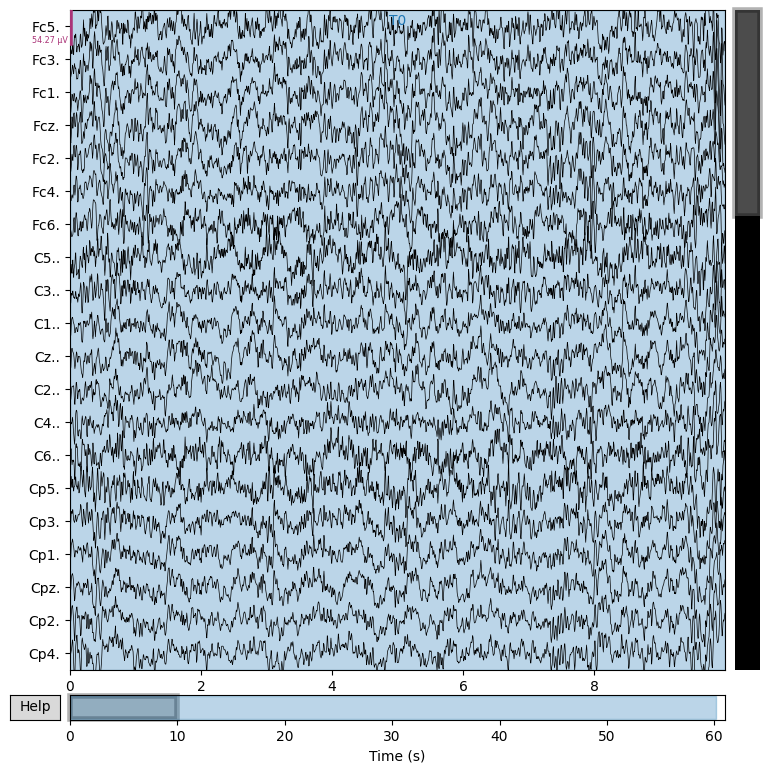

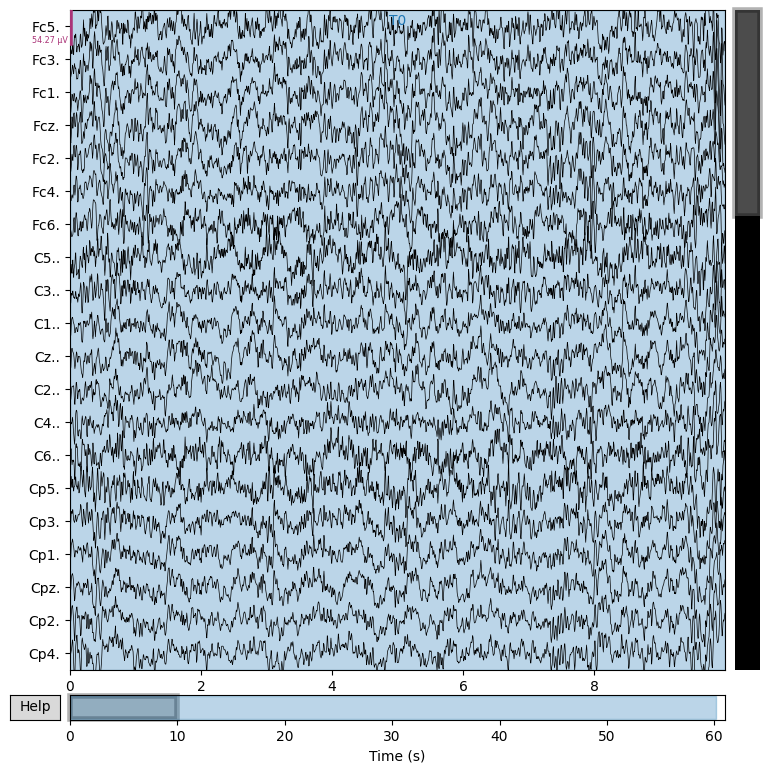

In [9]:
raw_prep = raw_eeg.copy()

# Average reference
raw_prep.set_eeg_reference('average')

# Band-pass filter for rhythms
raw_prep.filter(l_freq=1.0, h_freq=45.0)

# 50 Hz notch (mains interference)
raw_prep.notch_filter(freqs=[50.0])

raw_prep.plot(duration=10, n_channels=20, scalings='auto')


### Task 2: Student write-up (Short answers)
1. Why is **1–45 Hz** a reasonable range for rhythm analysis in this introductory lab?
2. What does the **50 Hz notch** filter remove, and why is it relevant in Sri Lanka?


**Answer (Task 2):**

1. **1-45 Hz** covers all the classic bands (delta to low gamma). The 1 Hz high-pass removes slow drift and
   DC offset, the 45 Hz low-pass removes muscle noise and mains. It is also safe at 160 Hz sampling (Nyquist = 80 Hz).
2. The **50 Hz notch** removes power-line (mains) hum from the AC supply. Sri Lanka's grid is 230 V / **50 Hz**,
   so the hum sits exactly at 50 Hz (in the USA you would need a 60 Hz notch instead).

#### 6) Power Spectral Density (PSD)
Compute PSD using Welch and plot mean PSD across channels.


In [10]:
# Keep only EEG channels for rhythm analysis
raw_psd = raw_prep.copy().pick_types(eeg=True, eog=False)

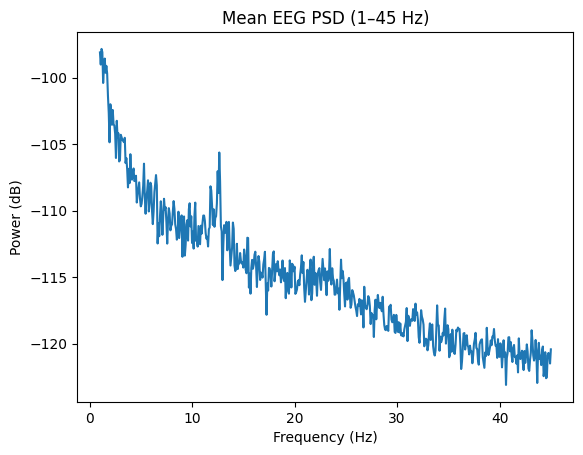

In [11]:
# Compute PSD using the modern MNE API

psd = raw_psd.compute_psd(
    method="welch",
    fmin=1,
    fmax=45,
    n_fft=2048
)

psds = psd.get_data()      # (n_channels, n_freqs)
freqs = psd.freqs

"""What this line does

Converts the power spectral density (PSD) values from a linear scale to a logarithmic (decibel) scale

Formula used: Power (dB) = 10 * log10(Power)"""
psds_db = 10 * np.log10(psds)

plt.figure()
plt.plot(freqs, psds_db.mean(axis=0))
plt.title("Mean EEG PSD (1–45 Hz)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.show()

### Task B2 (small code change + explanation)
1. Plot PSD for **one chosen channel** (pick a channel name you see in `raw_psd.ch_names`).
2. Write 2–3 lines: how does PSD help you identify rhythms?


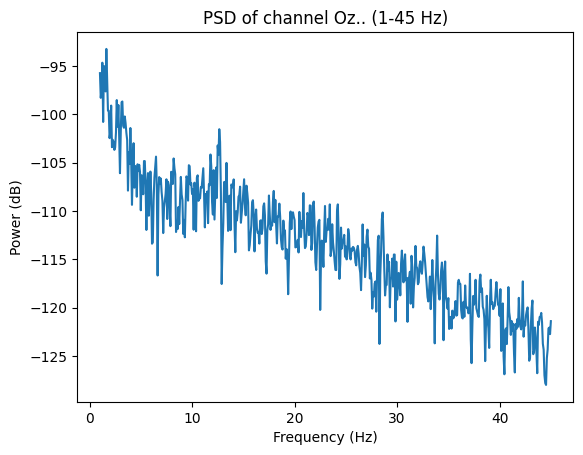

Available channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..'] ...


In [12]:
# Task B2: PSD of ONE chosen channel
# (any name from raw_psd.ch_names - "Oz.." is an occipital channel, good for alpha)
my_channel = "Oz.."
ch_index = raw_psd.ch_names.index(my_channel)

plt.figure()
plt.plot(freqs, psds_db[ch_index])
plt.title(f"PSD of channel {my_channel} (1-45 Hz)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.show()

print("Available channel names:", raw_psd.ch_names[:10], "...")

**Answer (Task B2):**

The raw trace mixes all rhythms together, so the PSD splits the signal by frequency and shows how much power
sits at each one. A rhythm that is really present then appears as a visible bump instead of staying hidden.
Here the `Oz..` curve falls off with frequency but rises again around **8-13 Hz**, which is the alpha rhythm.

#### 7) Band power features
We compute mean power in standard rhythm bands.


In [13]:
bands = {
    'delta': (1, 4),
    'theta': (4, 8),
    'alpha': (8, 12),
    'beta':  (13, 30),
    'gamma': (30, 45)
}

def bandpower_mean(psds, freqs, fmin, fmax):
    idx = (freqs >= fmin) & (freqs <= fmax)
    return psds[:, idx].mean(axis=1)


In [14]:
band_powers = {b: bandpower_mean(psds, freqs, lo, hi) for b, (lo, hi) in bands.items()}

alpha = band_powers['alpha']
top_idx = np.argsort(alpha)[-5:][::-1]

print('Top 5 channels by alpha band power:')
for i in top_idx:
    print(f"{raw_psd.ch_names[i]} : {alpha[i]:.3e}")


Top 5 channels by alpha band power:
O2.. : 1.928e-11
O1.. : 1.804e-11
Iz.. : 1.731e-11
Oz.. : 1.680e-11
Po8. : 1.649e-11


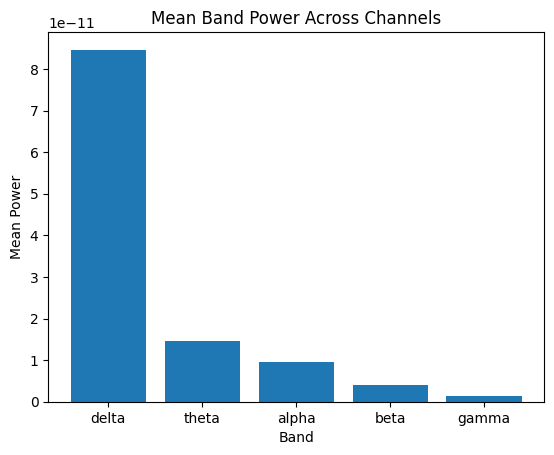

In [15]:
# Band power features (global band comparison)
band_means = []
band_names = []

for band, (lo, hi) in bands.items():
    bp = bandpower_mean(psds, freqs, lo, hi)
    band_means.append(bp.mean())
    band_names.append(band)

plt.figure()
plt.bar(band_names, band_means)
plt.title("Mean Band Power Across Channels")
plt.xlabel("Band")
plt.ylabel("Mean Power")
plt.show()

### Task B3
1. Compute and print **top-5 channels** for **Alpha** and **beta** band power too.
2. Briefly compare: alpha vs beta (relaxed vs active) using Week 1 rhythm theory.


In [16]:
# Task B3: top-5 channels for ALPHA and for BETA band power
alpha = band_powers['alpha']
beta = band_powers['beta']

top_alpha = np.argsort(alpha)[-5:][::-1]
top_beta = np.argsort(beta)[-5:][::-1]

print("Top 5 channels by ALPHA band power (8-12 Hz):")
for i in top_alpha:
    print(f"  {raw_psd.ch_names[i]} : {alpha[i]:.3e}")

print()
print("Top 5 channels by BETA band power (13-30 Hz):")
for i in top_beta:
    print(f"  {raw_psd.ch_names[i]} : {beta[i]:.3e}")

print()
print(f"Mean alpha over all channels: {alpha.mean():.3e}")
print(f"Mean beta  over all channels: {beta.mean():.3e}")
print(f"Alpha / Beta ratio          : {alpha.mean() / beta.mean():.2f}")

Top 5 channels by ALPHA band power (8-12 Hz):
  O2.. : 1.928e-11
  O1.. : 1.804e-11
  Iz.. : 1.731e-11
  Oz.. : 1.680e-11
  Po8. : 1.649e-11

Top 5 channels by BETA band power (13-30 Hz):
  T8.. : 1.268e-11
  Iz.. : 9.322e-12
  O2.. : 8.893e-12
  T10. : 8.199e-12
  O1.. : 7.676e-12

Mean alpha over all channels: 9.454e-12
Mean beta  over all channels: 3.909e-12
Alpha / Beta ratio          : 2.42


**Answer (Task B3):**

The top alpha channels are all occipital (`O2. O1. Iz. Oz. Po8.`), because alpha is the idling rhythm of the
visual cortex during relaxed wakefulness. The top beta channels are temporal (`T8. Iz. O2. T10. O1.`), and beta
marks an active, alert cortex (some of that `T8.` beta is probably jaw muscle). Mean alpha is **2.42x** mean beta,
so this is a relaxed baseline rather than an active task.

#### 8) Segment comparison: simple state inference workflow
We perform: **segmentation → feature extraction → comparison**.

You may adjust the time windows after visually inspecting the raw plots.


In [17]:
max_t = raw_psd.times[-1]

# pick two segments: [10%, 35%] and [55%, 80%] of the recording
segA = raw_psd.copy().crop(tmin=0.10 * max_t, tmax=0.35 * max_t)
segB = raw_psd.copy().crop(tmin=0.55 * max_t, tmax=0.80 * max_t)

print("Segment A:", 0.10*max_t, "to", 0.35*max_t)
print("Segment B:", 0.55*max_t, "to", 0.80*max_t)


Segment A: 6.099375 to 21.3478125
Segment B: 33.5465625 to 48.795


In [18]:
# --- Compute PSD for each segment using modern MNE API ---
psdA_obj = segA.compute_psd(method="welch", fmin=1, fmax=45, n_fft=2048)
psdB_obj = segB.compute_psd(method="welch", fmin=1, fmax=45, n_fft=2048)

psdA = psdA_obj.get_data()   # (n_channels, n_freqs)
psdB = psdB_obj.get_data()

freqsA = psdA_obj.freqs
freqsB = psdB_obj.freqs

# --- Alpha band power comparison (8–12 Hz) ---
alphaA = bandpower_mean(psdA, freqsA, 8, 12)
alphaB = bandpower_mean(psdB, freqsB, 8, 12)

diff = alphaB - alphaA

print("Mean alpha (Segment A):", alphaA.mean())
print("Mean alpha (Segment B):", alphaB.mean())
print("Mean (B - A):", diff.mean())

Mean alpha (Segment A): 1.0745958082612198e-11
Mean alpha (Segment B): 1.1448792597415341e-11
Mean (B - A): 7.028345148031425e-13


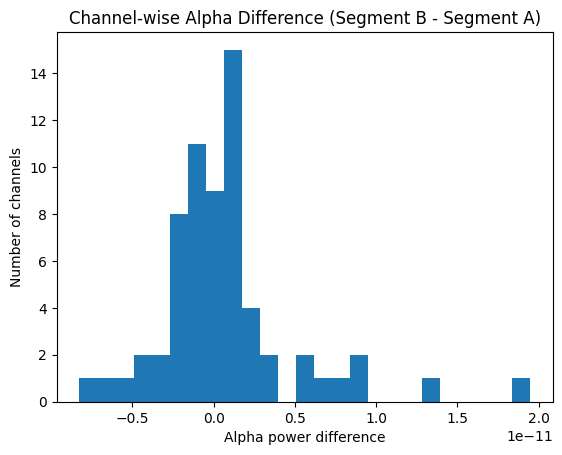

In [19]:
plt.figure()
plt.hist(diff, bins=25)
plt.title('Channel-wise Alpha Difference (Segment B - Segment A)')
plt.xlabel('Alpha power difference')
plt.ylabel('Number of channels')
plt.show()


#### Task B4
1. Replace alpha with **theta (4–8 Hz)** and compare segments again (compute + plot histogram).
2. Write a short conclusion:
   - Which segment looks more “relaxed”?
   - Which rhythms support your conclusion?


Mean theta (Segment A): 2.074472526640982e-11
Mean theta (Segment B): 2.5475492062833028e-11
Mean (B - A): 4.730766796423209e-12
Channels where B > A: 33 out of 64


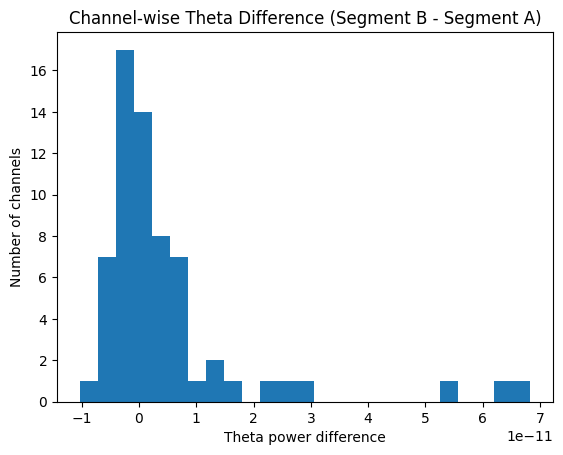

In [20]:
# Task B4: same segment comparison, but using THETA (4-8 Hz) instead of alpha
thetaA = bandpower_mean(psdA, freqsA, 4, 8)
thetaB = bandpower_mean(psdB, freqsB, 4, 8)

diff_theta = thetaB - thetaA

print("Mean theta (Segment A):", thetaA.mean())
print("Mean theta (Segment B):", thetaB.mean())
print("Mean (B - A):", diff_theta.mean())
print("Channels where B > A:", (diff_theta > 0).sum(), "out of", len(diff_theta))

plt.figure()
plt.hist(diff_theta, bins=25)
plt.title('Channel-wise Theta Difference (Segment B - Segment A)')
plt.xlabel('Theta power difference')
plt.ylabel('Number of channels')
plt.show()

**Answer (Task B4):**

- **Segment B** (33.5-48.8 s) looks slightly more relaxed than Segment A (6.1-21.3 s).
- Both slow rhythms support it: alpha is higher in B (+7.0e-13) and theta is higher in B (+4.7e-12), i.e. more
  idling and a little drowsiness after a minute of sitting still.
- But the effect is weak: only **33/64** channels show the theta increase and both histograms sit near zero.
  Both segments come from the same eyes-open run, so this is mostly normal fluctuation.

### 9) Final mini-report
Write **3 short paragraphs**:
1. Brain rhythms as a “language of the brain” 
2. How this pipeline could support BCI / health monitoring
3. One limitation of this lab’s segmentation approach, and how you would improve it in later weeks


### Answer - Final mini-report

**1. Brain rhythms as a "language of the brain".**
Large populations of neurons fire together in repeating waves, and EEG picks those waves up as rhythms.
Each band is a different word: delta for deep sleep, theta for drowsiness, alpha for relaxed idling, beta for
alert processing and gamma for fine binding of information. We could read that language directly in this lab,
because alpha was strongest at the occipital electrodes (the visual cortex idling) and mean alpha was 2.42x mean
beta. So frequency, amplitude and scalp location together turn a wiggly voltage trace into a statement about
brain state.

**2. How this pipeline could support BCI / health monitoring.**
The steps here (load, re-reference, filter, PSD, band power) are the front end of almost every real BCI.
Once the signal becomes a few numbers per channel per band, a classifier can learn from them, which is how
motor-imagery BCIs move a cursor or a wheelchair using runs 3-14 of this same dataset. The same band powers are
used clinically for sleep staging, driver drowsiness alerts, depth of anaesthesia and epilepsy screening.
Because the features are cheap to compute on short windows, the whole thing can run in near real time on a
small device.

**3. One limitation of this lab's segmentation approach.**
The segmentation is arbitrary: we cut at fixed percentages of one run, so Segment A and Segment B are both
eyes-open and have no reason to differ. That is why the alpha and theta differences were tiny and only about
half the channels agreed, meaning we mostly measured noise and artifacts. Two long windows also give just one
number per channel, so we cannot test whether the difference is real. In later weeks I would compare Run 1
(eyes open) vs Run 2 (eyes closed), cut each run into many short overlapping epochs so each condition gives a
distribution for a statistical test, add artifact rejection, and average across several subjects.